# Net worth over time

Reads the latest run file under `data/shared/state/runs/` and plots month-end net worth (nominal) plus an inflation-adjusted (CPI) series when available.

The run file is opened read-only and exposes pre-built views (`net_worth`, `net_worth_constant_cpi`) — see ADR-002.


In [1]:
import sqlite3
from pathlib import Path

import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUNS_DIR = REPO / "data" / "shared" / "state" / "runs"

run_files = sorted(RUNS_DIR.glob("*.sqlite3"))
if not run_files:
    raise FileNotFoundError(f"no run files under {RUNS_DIR}")
RUN_FILE = run_files[-1]
print(f"latest run: {RUN_FILE.name}")


latest run: 2026-05-21T082804Z_current_cf427bd.sqlite3


In [2]:
con = sqlite3.connect(f"file:{RUN_FILE}?mode=ro", uri=True)

run_meta = pd.read_sql(
    "SELECT scenario_name, status, started_at, finished_at, "
    "       substr(code_version,1,12) AS code, code_dirty, "
    "       substr(data_version,1,12) AS data, data_dirty, data_mode, run_by "
    "FROM simulation_run WHERE id = 1",
    con,
)
run_meta.T


,0
scenario_name,current
status,succeeded
started_at,2026-05-21T08:28:04Z
finished_at,2026-05-21T08:28:04Z
code,99b36a0ae89e
code_dirty,1
data,cf427bd52aa5
data_dirty,1
data_mode,live
run_by,rwk


In [3]:
# Pull net worth (nominal) and, when present, CPI-constant dollars.
nw = pd.read_sql(
    "SELECT month, net_worth AS nominal_cents FROM net_worth ORDER BY month",
    con,
)
try:
    cpi = pd.read_sql(
        "SELECT month, constant_cents FROM net_worth_constant_cpi ORDER BY month",
        con,
    )
    nw = nw.merge(cpi, on="month", how="left")
except pd.io.sql.DatabaseError:
    nw["constant_cents"] = pd.NA

nw["month"] = pd.to_datetime(nw["month"])
nw["nominal"] = nw["nominal_cents"] / 100
nw["cpi_constant"] = nw["constant_cents"].astype("Float64") / 100
nw = nw.set_index("month")
nw[["nominal", "cpi_constant"]].head()


,nominal,cpi_constant
month,,
2026-05-31,3746905.27,3737561.36
2026-06-30,3769444.27,3750668.42
2026-07-31,3792079.16,3763783.03
2026-08-31,3814810.33,3776905.3
2026-09-30,3837644.91,3790038.23


## Year-end net worth (table)


In [4]:
year_end = (
    nw.groupby(nw.index.year)
      .tail(1)
      .assign(year=lambda d: d.index.year)
      .set_index("year")[["nominal", "cpi_constant"]]
)
year_end.style.format({"nominal": "${:,.0f}", "cpi_constant": "${:,.0f}"})


,nominal,cpi_constant
year,,
2026,"$3,906,310","$3,829,066"
2027,"$4,120,543","$3,919,862"
2028,"$4,313,025","$3,981,880"
2029,"$4,517,565","$4,047,627"
2030,"$4,734,865","$4,117,116"
2031,"$4,965,670","$4,190,375"
2032,"$5,210,769","$4,267,432"
2033,"$5,470,998","$4,348,315"
2034,"$5,747,242","$4,433,061"


## Monthly net worth (chart)


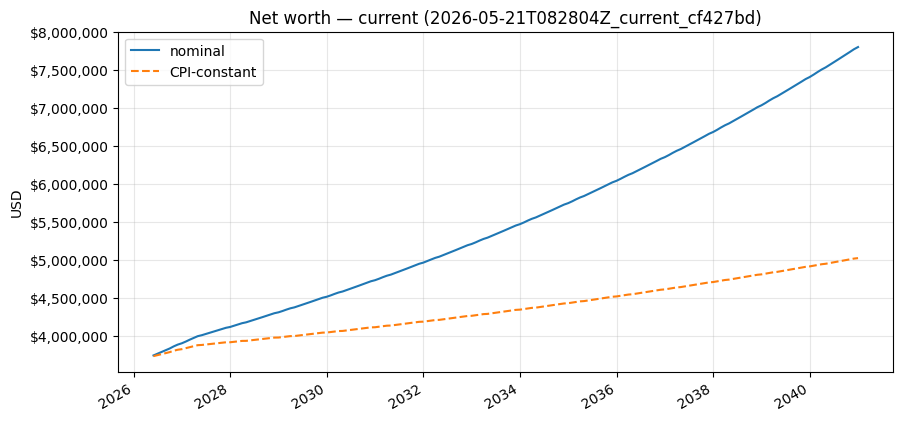

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(nw.index, nw["nominal"], label="nominal")
if nw["cpi_constant"].notna().any():
    ax.plot(nw.index, nw["cpi_constant"], label="CPI-constant", linestyle="--")
ax.set_title(
    f"Net worth — {run_meta.loc[0, 'scenario_name']} "
    f"({RUN_FILE.stem})"
)
ax.set_ylabel("USD")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.grid(True, alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.show()


## Income by category

Income flows are transfers _out of_ accounts with `kind = 'income'`. Subkinds are bucketed:

- **salary** — `salary`
- **investment** — `interest`, `dividend`, `capital_gain`
- **other** — `ss_benefit`, `pension`, `rental`, `other_income`


In [6]:
income_sql = """
SELECT s.month,
       CASE a.subkind
         WHEN 'salary'        THEN 'salary'
         WHEN 'interest'      THEN 'investment'
         WHEN 'dividend'      THEN 'investment'
         WHEN 'capital_gain'  THEN 'investment'
         ELSE 'other'
       END AS category,
       SUM(te.amount) AS cents
FROM transfer_event te
JOIN simulation_step s ON s.id = te.step_id
JOIN account a         ON a.id = te.from_account
WHERE a.kind = 'income'
GROUP BY s.month, category
"""
income_raw = pd.read_sql(income_sql, con)
income_raw["month"] = pd.to_datetime(income_raw["month"])
income = (
    income_raw.pivot_table(
        index="month", columns="category", values="cents",
        aggfunc="sum", fill_value=0,
    )
    .reindex(columns=["salary", "investment", "other"], fill_value=0)
    / 100
)
income["total"] = income.sum(axis=1)
income.head()


category,salary,investment,other,total
month,,,,
2026-05-31,10574.6,9842.55,2825.0,23242.15
2026-06-30,10574.6,9938.00,2825.0,23337.60
2026-07-31,10574.6,10033.89,2825.0,23433.49
2026-08-31,10574.6,10130.17,2825.0,23529.77
2026-09-30,10574.6,10233.58,2825.0,23633.18


In [7]:
income_yearly = income.groupby(income.index.year).sum()
income_yearly.index.name = "year"
income_yearly.style.format("${:,.0f}")


category,salary,investment,other,total
year,,,,
2026,"$89,884","$81,553","$22,600","$194,037"
2027,"$47,586","$134,154","$53,676","$235,416"
2028,$0,"$145,863","$67,802","$213,665"
2029,$0,"$157,921","$67,802","$225,723"
2030,$0,"$170,681","$67,802","$238,483"
2031,$0,"$184,186","$67,802","$251,988"
2032,$0,"$198,480","$67,802","$266,282"
2033,$0,"$213,609","$67,802","$281,412"
2034,$0,"$229,625","$67,802","$297,427"


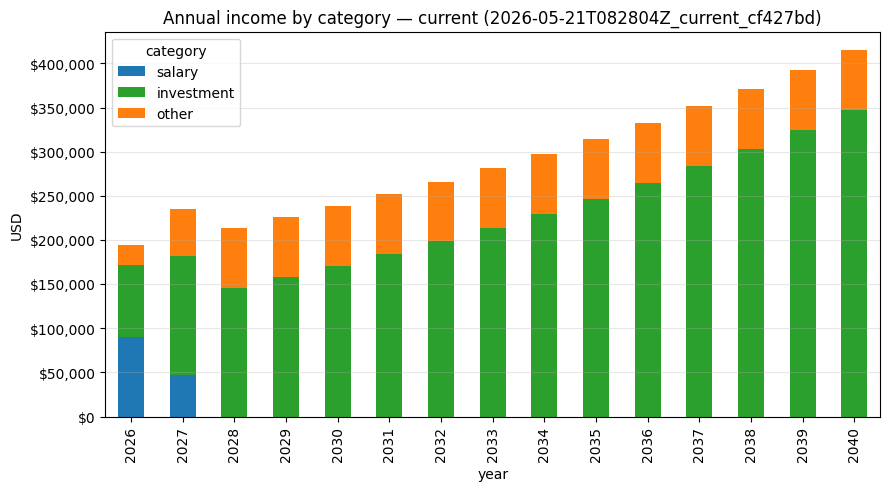

In [8]:
categories = ["salary", "investment", "other"]
fig, ax = plt.subplots(figsize=(10, 5))
income_yearly[categories].plot(
    kind="bar", stacked=True, ax=ax,
    color=["#1f77b4", "#2ca02c", "#ff7f0e"],
)
ax.set_title(
    f"Annual income by category — {run_meta.loc[0, 'scenario_name']} "
    f"({RUN_FILE.stem})"
)
ax.set_xlabel("year")
ax.set_ylabel("USD")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.grid(True, axis="y", alpha=0.3)
ax.legend(title="category")
plt.show()
